In [1]:
# Generate a dataset

# Fit three classifiers

# To make a prediction - pick max 

In [10]:
import numpy as np
from sklearn.datasets import make_classification
import pandas as pd
import matplotlib.pyplot as plt

# Generate a synthetic dataset
X, y = make_classification(n_samples=1000, n_features=20, n_classes=2, n_clusters_per_class=2, random_state=42)

# Convert to a DataFrame for convenience
df = pd.DataFrame(X, columns=[f'Feature_{i}' for i in range(X.shape[1])])
df['Target'] = y

print(df.head())

   Feature_0  Feature_1  Feature_2  Feature_3  Feature_4  Feature_5  \
0  -0.669356  -1.495778  -0.870766   1.141831   0.021606   1.730630   
1   0.093372   0.785848   0.105754   1.272354  -0.846316  -0.979093   
2  -0.905797  -0.608341   0.295141   0.943716   0.092936   1.370397   
3  -0.585793   0.389279   0.698816   0.436236  -0.315082   0.459505   
4   1.146441   0.515579  -1.222895  -0.396230  -1.293508  -0.352428   

   Feature_6  Feature_7  Feature_8  Feature_9  ...  Feature_11  Feature_12  \
0  -1.251698   0.289305   0.357163  -0.196811  ...    0.154850   -0.219970   
1   1.263707   0.264020   2.411677  -0.960046  ...    0.199810    0.288724   
2  -0.064772   0.287273  -0.533004  -0.032504  ...   -0.510064   -0.868768   
3   1.448820   0.505558  -1.440982  -1.134020  ...    1.466783    0.678728   
4   0.071254   1.239584   1.007133  -1.479444  ...   -0.918127    0.604121   

   Feature_13  Feature_14  Feature_15  Feature_16  Feature_17  Feature_18  \
0   -0.739137    1.802012  

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Split the dataset into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Initialize classifiers
clf1 = LogisticRegression(max_iter=1000, random_state=42)
clf2 = DecisionTreeClassifier(random_state=42)
clf3 = RandomForestClassifier(n_estimators=100, random_state=42)

# Fit classifiers
clf1.fit(X_train, y_train)
clf2.fit(X_train, y_train)
clf3.fit(X_train, y_train)

# Predict on test set
y_pred1 = clf1.predict_proba(X_test)[:, 1]  # Probabilities for the positive class
y_pred2 = clf2.predict_proba(X_test)[:, 1]
y_pred3 = clf3.predict_proba(X_test)[:, 1]

# Print accuracy scores
print(f'Logistic Regression Accuracy: {accuracy_score(y_test, clf1.predict(X_test))}')
print(f'Decision Tree Accuracy: {accuracy_score(y_test, clf2.predict(X_test))}')
print(f'Random Forest Accuracy: {accuracy_score(y_test, clf3.predict(X_test))}')

Logistic Regression Accuracy: 0.85
Decision Tree Accuracy: 0.8566666666666667
Random Forest Accuracy: 0.8566666666666667


In [12]:
# Combine predictions
combined_predictions = np.array([y_pred1, y_pred2, y_pred3])

# Predict by picking the classifier with the maximum probability
def predict_max_proba(predictions):
    return np.argmax(predictions, axis=0)

# Make predictions
final_predictions = predict_max_proba(combined_predictions)

# Convert predictions to classes
final_classes = np.array([0, 1, 2])  # Assuming three classifiers, but we need to pick based on max
predicted_classes = final_classes[final_predictions]

# Print a few predicted classes
print(f'Predicted classes for the first few samples: {predicted_classes[:10]}')

# Calculate and print the accuracy of the combined prediction
combined_accuracy = accuracy_score(y_test, predicted_classes)
print(f'Combined Classifier Accuracy: {combined_accuracy}')

Predicted classes for the first few samples: [1 1 0 1 1 0 0 1 1 0]
Combined Classifier Accuracy: 0.66


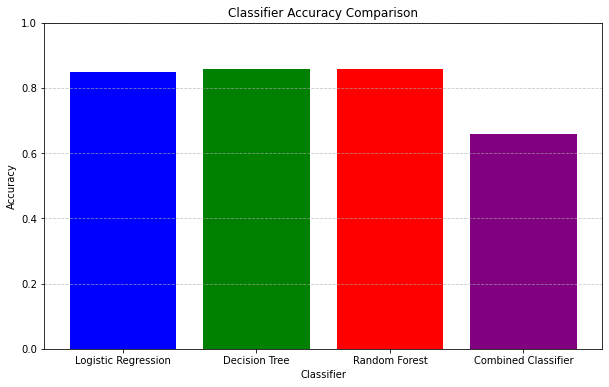

In [14]:
# Print accuracy scores
accuracy_lr = accuracy_score(y_test, clf1.predict(X_test))
accuracy_dt = accuracy_score(y_test, clf2.predict(X_test))
accuracy_rf = accuracy_score(y_test, clf3.predict(X_test))
# Visualization
plt.figure(figsize=(10, 6))
classifiers = ['Logistic Regression', 'Decision Tree', 'Random Forest', 'Combined Classifier']
accuracies = [accuracy_lr, accuracy_dt, accuracy_rf, combined_accuracy]

plt.bar(classifiers, accuracies, color=['blue', 'green', 'red', 'purple'])
plt.xlabel('Classifier')
plt.ylabel('Accuracy')
plt.title('Classifier Accuracy Comparison')
plt.ylim(0, 1)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()